In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv(
    "/Volumes/Backup Plus/vaccine thesis/data/processed/vaers_2025_model_data.csv"
)

print("Dataset shape:", data.shape)
print(data.head())

Dataset shape: (40919, 63)
   AGE_YRS  NUMDAYS  HAS_HISTORY  HAS_ALLERGY  SEX_M  SEX_Unknown  STATE_AL  \
0     37.0      0.0            0            0  False        False     False   
1     57.0      0.0            1            1  False        False     False   
2      1.0      0.0            0            0  False         True     False   
3      0.5      0.0            0            0  False        False     False   
4      2.0      0.0            0            0  False        False     False   

   STATE_AR  STATE_AS  STATE_AZ  ...  STATE_UT  STATE_Unknown  STATE_VA  \
0     False     False     False  ...     False          False     False   
1     False     False     False  ...     False          False     False   
2     False     False     False  ...     False          False     False   
3     False     False     False  ...     False          False     False   
4     False     False     False  ...     False          False      True   

   STATE_VI  STATE_VT  STATE_WA  STATE_WI  STAT

In [3]:
print(data.dtypes.value_counts())
print("\nMissing values:")
print(data.isna().sum().sum())

bool       58
int64       3
float64     2
Name: count, dtype: int64

Missing values:
0


In [4]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=["SEVERE"])
y = data["SEVERE"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

Training set: (32735, 62)
Test set: (8184, 62)

Training target distribution:
SEVERE
0    0.937651
1    0.062349
Name: proportion, dtype: float64

Test target distribution:
SEVERE
0    0.937683
1    0.062317
Name: proportion, dtype: float64


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

log_reg = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

log_reg.fit(X_train, y_train)

y_pred_lr = log_reg.predict(X_test)
y_prob_lr = log_reg.predict_proba(X_test)[:, 1]

print("Logistic Regression Results")
print("=" * 50)

print(classification_report(y_test, y_pred_lr, digits=4))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob_lr), 4))

Logistic Regression Results
              precision    recall  f1-score   support

           0     0.9603    0.7024    0.8113      7674
           1     0.1116    0.5627    0.1863       510

    accuracy                         0.6937      8184
   macro avg     0.5360    0.6326    0.4988      8184
weighted avg     0.9074    0.6937    0.7724      8184

Confusion Matrix:
[[5390 2284]
 [ 223  287]]
ROC-AUC: 0.6825
PR-AUC: 0.197


In [6]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print("Random Forest Results")
print("=" * 50)

print(classification_report(y_test, y_pred_rf, digits=4))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob_rf), 4))

Random Forest Results
              precision    recall  f1-score   support

           0     0.9592    0.9100    0.9339      7674
           1     0.2356    0.4176    0.3013       510

    accuracy                         0.8793      8184
   macro avg     0.5974    0.6638    0.6176      8184
weighted avg     0.9141    0.8793    0.8945      8184

Confusion Matrix:
[[6983  691]
 [ 297  213]]
ROC-AUC: 0.7646
PR-AUC: 0.3026


In [7]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf)
    ],
    "PR_AUC": [
        average_precision_score(y_test, y_prob_lr),
        average_precision_score(y_test, y_prob_rf)
    ]
})

results = results.sort_values(
    "PR_AUC",
    ascending=False
)

print(results)

                 Model   ROC_AUC    PR_AUC
1        Random Forest  0.764559  0.302577
0  Logistic Regression  0.682549  0.196950


In [8]:
# Random Forest feature importance

feature_importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Top 20 features:")
print(feature_importance.head(20))

Top 20 features:
AGE_YRS          0.338632
NUMDAYS          0.319471
HAS_HISTORY      0.051646
SEX_M            0.031297
HAS_ALLERGY      0.022416
STATE_Unknown    0.014181
STATE_CA         0.012891
SEX_Unknown      0.011949
STATE_IA         0.009908
STATE_FL         0.009145
STATE_NY         0.007210
STATE_TX         0.007083
STATE_NC         0.007028
STATE_MI         0.006842
STATE_IL         0.006499
STATE_PA         0.006480
STATE_OH         0.006290
STATE_VA         0.006094
STATE_MA         0.005763
STATE_GA         0.005703
dtype: float64


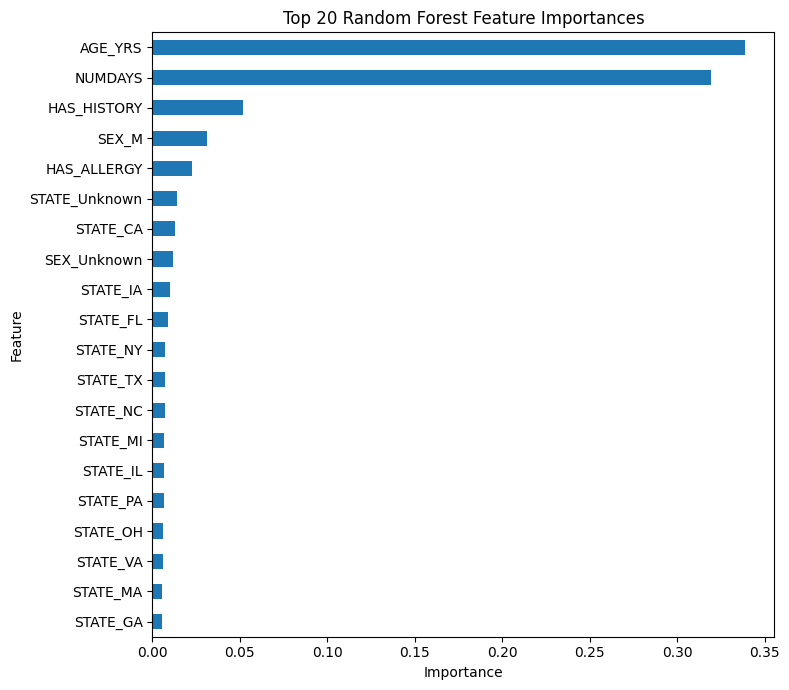

In [9]:
import matplotlib.pyplot as plt

feature_importance.head(20).sort_values().plot(
    kind="barh",
    figsize=(8, 7)
)

plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf)
    ],
    
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf)
    ],
    
    "F1": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf)
    ],
    
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf)
    ],
    
    "PR-AUC": [
        average_precision_score(y_test, y_prob_lr),
        average_precision_score(y_test, y_prob_rf)
    ]
})

results = results.round(4)

print(results)

                 Model  Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC
0  Logistic Regression    0.6937     0.1116  0.5627  0.1863   0.6825  0.1970
1        Random Forest    0.8793     0.2356  0.4176  0.3013   0.7646  0.3026


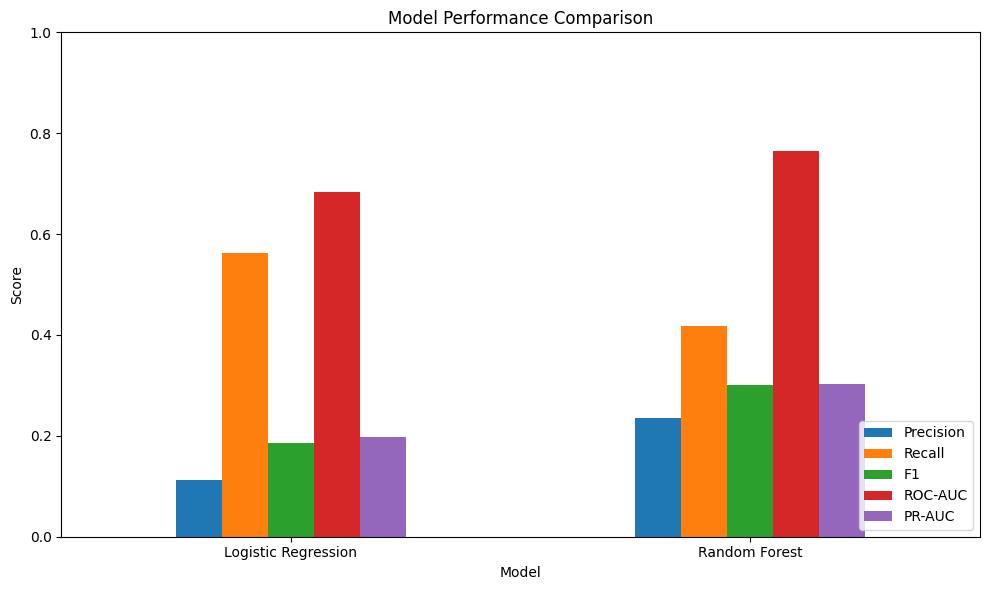

In [11]:
results.set_index("Model")[[
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC"
]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [12]:
%pip install xgboost


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [13]:
from xgboost import XGBClassifier

print("XGBoost installed successfully")

XGBoost installed successfully


In [14]:
from xgboost import XGBClassifier

In [15]:
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)
y_prob_xgb = xgb.predict_proba(X_test)[:, 1]

In [16]:
print("XGBoost Results")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred_xgb,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, y_prob_xgb), 4)
)

print(
    "PR-AUC:",
    round(average_precision_score(y_test, y_prob_xgb), 4)
)

XGBoost Results
              precision    recall  f1-score   support

           0     0.9454    0.9960    0.9700      7674
           1     0.6900    0.1353    0.2262       510

    accuracy                         0.9423      8184
   macro avg     0.8177    0.5656    0.5981      8184
weighted avg     0.9295    0.9423    0.9237      8184

Confusion Matrix:
[[7643   31]
 [ 441   69]]
ROC-AUC: 0.7942
PR-AUC: 0.3431


In [17]:
print("Logistic Regression:", "y_prob_lr" in globals())
print("Random Forest:", "y_prob_rf" in globals())
print("XGBoost:", "y_prob_xgb" in globals())

Logistic Regression: True
Random Forest: True
XGBoost: True


In [18]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
    ],

    "F1": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_xgb)
    ],

    "PR-AUC": [
        average_precision_score(y_test, y_prob_lr),
        average_precision_score(y_test, y_prob_rf),
        average_precision_score(y_test, y_prob_xgb)
    ]
})

model_comparison = model_comparison.round(4)

print(model_comparison)

                 Model  Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC
0  Logistic Regression    0.6937     0.1116  0.5627  0.1863   0.6825  0.1970
1        Random Forest    0.8793     0.2356  0.4176  0.3013   0.7646  0.3026
2              XGBoost    0.9423     0.6900  0.1353  0.2262   0.7942  0.3431


In [19]:
%pip install imbalanced-learn


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [20]:
from imblearn.over_sampling import RandomOverSampler

In [21]:
print("Before oversampling:")
print(y_train.value_counts())

Before oversampling:
SEVERE
0    30694
1     2041
Name: count, dtype: int64


In [22]:
ros = RandomOverSampler(
    random_state=42
)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train,
    y_train
)

print("After oversampling:")
print(y_train_balanced.value_counts())

After oversampling:
SEVERE
1    30694
0    30694
Name: count, dtype: int64


In [23]:
print("Original training:", X_train.shape)
print("Balanced training:", X_train_balanced.shape)
print("Test:", X_test.shape)

Original training: (32735, 62)
Balanced training: (61388, 62)
Test: (8184, 62)


In [24]:
log_reg_balanced = LogisticRegression(
    max_iter=2000,
    random_state=42
)

log_reg_balanced.fit(
    X_train_balanced,
    y_train_balanced
)

y_pred_lr_balanced = log_reg_balanced.predict(X_test)
y_prob_lr_balanced = log_reg_balanced.predict_proba(X_test)[:, 1]

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [25]:
print("Balanced Logistic Regression")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred_lr_balanced,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_lr_balanced
))

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, y_prob_lr_balanced), 4)
)

print(
    "PR-AUC:",
    round(average_precision_score(
        y_test,
        y_prob_lr_balanced
    ), 4)
)

Balanced Logistic Regression
              precision    recall  f1-score   support

           0     0.9602    0.7015    0.8107      7674
           1     0.1113    0.5627    0.1859       510

    accuracy                         0.6928      8184
   macro avg     0.5358    0.6321    0.4983      8184
weighted avg     0.9073    0.6928    0.7718      8184

Confusion Matrix:
[[5383 2291]
 [ 223  287]]
ROC-AUC: 0.6807
PR-AUC: 0.1966


In [26]:
rf_balanced = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(
    X_train_balanced,
    y_train_balanced
)

y_pred_rf_balanced = rf_balanced.predict(X_test)
y_prob_rf_balanced = rf_balanced.predict_proba(X_test)[:, 1]

In [27]:
print("Balanced Random Forest")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred_rf_balanced,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_rf_balanced
))

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, y_prob_rf_balanced), 4)
)

print(
    "PR-AUC:",
    round(average_precision_score(
        y_test,
        y_prob_rf_balanced
    ), 4)
)

Balanced Random Forest
              precision    recall  f1-score   support

           0     0.9579    0.8830    0.9189      7674
           1     0.1910    0.4157    0.2617       510

    accuracy                         0.8539      8184
   macro avg     0.5744    0.6493    0.5903      8184
weighted avg     0.9101    0.8539    0.8780      8184

Confusion Matrix:
[[6776  898]
 [ 298  212]]
ROC-AUC: 0.7559
PR-AUC: 0.2605


In [28]:
xgb_balanced = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_balanced.fit(
    X_train_balanced,
    y_train_balanced
)

y_pred_xgb_balanced = xgb_balanced.predict(X_test)
y_prob_xgb_balanced = xgb_balanced.predict_proba(X_test)[:, 1]

In [29]:
print("Balanced XGBoost")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred_xgb_balanced,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_xgb_balanced
))

print(
    "ROC-AUC:",
    round(roc_auc_score(
        y_test,
        y_prob_xgb_balanced
    ), 4)
)

print(
    "PR-AUC:",
    round(average_precision_score(
        y_test,
        y_prob_xgb_balanced
    ), 4)
)

Balanced XGBoost
              precision    recall  f1-score   support

           0     0.9674    0.8421    0.9004      7674
           1     0.1941    0.5725    0.2900       510

    accuracy                         0.8253      8184
   macro avg     0.5808    0.7073    0.5952      8184
weighted avg     0.9192    0.8253    0.8623      8184

Confusion Matrix:
[[6462 1212]
 [ 218  292]]
ROC-AUC: 0.7845
PR-AUC: 0.3388


In [30]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_balanced)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Scaled training shape: (61388, 62)
Scaled test shape: (8184, 62)


In [31]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    batch_size=128,
    learning_rate_init=0.001,
    max_iter=100,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)

mlp.fit(
    X_train_scaled,
    y_train_balanced
)

print("MLP training completed.")

MLP training completed.


In [32]:
y_pred_mlp = mlp.predict(X_test_scaled)
y_prob_mlp = mlp.predict_proba(X_test_scaled)[:, 1]
print("MLP Results")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred_mlp,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_mlp
))

print(
    "ROC-AUC:",
    round(roc_auc_score(
        y_test,
        y_prob_mlp
    ), 4)
)

print(
    "PR-AUC:",
    round(average_precision_score(
        y_test,
        y_prob_mlp
    ), 4)
)

MLP Results
              precision    recall  f1-score   support

           0     0.9598    0.7707    0.8549      7674
           1     0.1296    0.5137    0.2070       510

    accuracy                         0.7546      8184
   macro avg     0.5447    0.6422    0.5309      8184
weighted avg     0.9080    0.7546    0.8145      8184

Confusion Matrix:
[[5914 1760]
 [ 248  262]]
ROC-AUC: 0.6743
PR-AUC: 0.2264


In [33]:
baseline_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "MLP"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_mlp)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb),
        precision_score(y_test, y_pred_mlp)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb),
        recall_score(y_test, y_pred_mlp)
    ],

    "F1": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb),
        f1_score(y_test, y_pred_mlp)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_xgb),
        roc_auc_score(y_test, y_prob_mlp)
    ],

    "PR-AUC": [
        average_precision_score(y_test, y_prob_lr),
        average_precision_score(y_test, y_prob_rf),
        average_precision_score(y_test, y_prob_xgb),
        average_precision_score(y_test, y_prob_mlp)
    ]
})

baseline_comparison = baseline_comparison.round(4)

print(baseline_comparison)

                 Model  Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC
0  Logistic Regression    0.6937     0.1116  0.5627  0.1863   0.6825  0.1970
1        Random Forest    0.8793     0.2356  0.4176  0.3013   0.7646  0.3026
2              XGBoost    0.9423     0.6900  0.1353  0.2262   0.7942  0.3431
3                  MLP    0.7546     0.1296  0.5137  0.2070   0.6743  0.2264


In [34]:
import os

os.makedirs("../results", exist_ok=True)

baseline_comparison.to_csv(
    "../results/baseline_model_comparison.csv",
    index=False
)

print("Baseline comparison saved.")

Baseline comparison saved.


In [35]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

In [36]:
lr_param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear", "lbfgs"]
}

lr_grid = GridSearchCV(
    LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    param_grid=lr_param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print("Best parameters:")
print(lr_grid.best_params_)

print("\nBest CV ROC-AUC:")
print(round(lr_grid.best_score_, 4))

Best parameters:
{'C': 0.1, 'solver': 'liblinear'}

Best CV ROC-AUC:
0.6792


In [37]:
best_lr = lr_grid.best_estimator_

y_pred_lr_tuned = best_lr.predict(X_test)
y_prob_lr_tuned = best_lr.predict_proba(X_test)[:, 1]

print("Tuned Logistic Regression")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred_lr_tuned,
    digits=4
))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob_lr_tuned), 4))

print("PR-AUC:",
      round(average_precision_score(
          y_test,
          y_prob_lr_tuned
      ), 4))

Tuned Logistic Regression
              precision    recall  f1-score   support

           0     0.9380    0.9997    0.9679      7674
           1     0.6000    0.0059    0.0117       510

    accuracy                         0.9378      8184
   macro avg     0.7690    0.5028    0.4898      8184
weighted avg     0.9169    0.9378    0.9083      8184

ROC-AUC: 0.6453
PR-AUC: 0.1676


In [38]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

rf_param_grid = {
    "n_estimators": [200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", "log2"]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    param_grid=rf_param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best parameters:")
print(rf_grid.best_params_)

print("\nBest CV ROC-AUC:")
print(round(rf_grid.best_score_, 4))

Best parameters:
{'max_depth': 20, 'max_features': 'log2', 'min_samples_leaf': 5, 'n_estimators': 300}

Best CV ROC-AUC:
0.7912


In [39]:
best_rf = rf_grid.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test)
y_prob_rf_tuned = best_rf.predict_proba(X_test)[:, 1]

print("Tuned Random Forest")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred_rf_tuned,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_tuned))

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, y_prob_rf_tuned), 4)
)

print(
    "PR-AUC:",
    round(average_precision_score(y_test, y_prob_rf_tuned), 4)
)

Tuned Random Forest
              precision    recall  f1-score   support

           0     0.9657    0.8666    0.9135      7674
           1     0.2111    0.5373    0.3031       510

    accuracy                         0.8460      8184
   macro avg     0.5884    0.7019    0.6083      8184
weighted avg     0.9187    0.8460    0.8754      8184

Confusion Matrix:
[[6650 1024]
 [ 236  274]]
ROC-AUC: 0.7876
PR-AUC: 0.3351


In [40]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

In [41]:
xgb_param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 10]
}

In [42]:
xgb_random = RandomizedSearchCV(
    XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=xgb_param_dist,
    n_iter=30,
    scoring="roc_auc",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_random.fit(X_train, y_train)

print("Best parameters:")
print(xgb_random.best_params_)

print("\nBest CV ROC-AUC:")
print(round(xgb_random.best_score_, 4))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters:
{'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.9}

Best CV ROC-AUC:
0.7962


In [43]:
best_xgb = xgb_random.best_estimator_

y_pred_xgb_tuned = best_xgb.predict(X_test)
y_prob_xgb_tuned = best_xgb.predict_proba(X_test)[:, 1]

print("Tuned XGBoost")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred_xgb_tuned,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_xgb_tuned
))

print(
    "ROC-AUC:",
    round(roc_auc_score(
        y_test,
        y_prob_xgb_tuned
    ), 4)
)

print(
    "PR-AUC:",
    round(average_precision_score(
        y_test,
        y_prob_xgb_tuned
    ), 4)
)

Tuned XGBoost
              precision    recall  f1-score   support

           0     0.9446    0.9973    0.9702      7674
           1     0.7439    0.1196    0.2061       510

    accuracy                         0.9426      8184
   macro avg     0.8442    0.5584    0.5881      8184
weighted avg     0.9321    0.9426    0.9226      8184

Confusion Matrix:
[[7653   21]
 [ 449   61]]
ROC-AUC: 0.7964
PR-AUC: 0.3443


In [44]:
best_xgb_params = xgb_random.best_params_

xgb_balanced_tuned = XGBClassifier(
    **best_xgb_params,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_balanced_tuned.fit(
    X_train_balanced,
    y_train_balanced
)

y_pred_xgb_bt = xgb_balanced_tuned.predict(X_test)
y_prob_xgb_bt = xgb_balanced_tuned.predict_proba(X_test)[:, 1]

In [45]:
print("Tuned + Balanced XGBoost")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred_xgb_bt,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_xgb_bt
))

print(
    "ROC-AUC:",
    round(roc_auc_score(
        y_test,
        y_prob_xgb_bt
    ), 4)
)

print(
    "PR-AUC:",
    round(average_precision_score(
        y_test,
        y_prob_xgb_bt
    ), 4)
)

Tuned + Balanced XGBoost
              precision    recall  f1-score   support

           0     0.9670    0.8441    0.9014      7674
           1     0.1946    0.5667    0.2897       510

    accuracy                         0.8269      8184
   macro avg     0.5808    0.7054    0.5956      8184
weighted avg     0.9189    0.8269    0.8633      8184

Confusion Matrix:
[[6478 1196]
 [ 221  289]]
ROC-AUC: 0.7917
PR-AUC: 0.3435


In [46]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "MLP",
        "Tuned Logistic Regression",
        "Tuned Random Forest",
        "Balanced Logistic Regression",
        "Balanced Random Forest",
        "Balanced XGBoost",
        "Tuned + Balanced XGBoost"
    ],
    
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_mlp),
        accuracy_score(y_test, y_pred_lr_tuned),
        accuracy_score(y_test, y_pred_rf_tuned),
        accuracy_score(y_test, y_pred_lr_balanced),
        accuracy_score(y_test, y_pred_rf_balanced),
        accuracy_score(y_test, y_pred_xgb_balanced),
        accuracy_score(y_test, y_pred_xgb_bt)
    ],
    
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb),
        precision_score(y_test, y_pred_mlp),
        precision_score(y_test, y_pred_lr_tuned),
        precision_score(y_test, y_pred_rf_tuned),
        precision_score(y_test, y_pred_lr_balanced),
        precision_score(y_test, y_pred_rf_balanced),
        precision_score(y_test, y_pred_xgb_balanced),
        precision_score(y_test, y_pred_xgb_bt)
    ],
    
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb),
        recall_score(y_test, y_pred_mlp),
        recall_score(y_test, y_pred_lr_tuned),
        recall_score(y_test, y_pred_rf_tuned),
        recall_score(y_test, y_pred_lr_balanced),
        recall_score(y_test, y_pred_rf_balanced),
        recall_score(y_test, y_pred_xgb_balanced),
        recall_score(y_test, y_pred_xgb_bt)
    ],
    
    "F1": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb),
        f1_score(y_test, y_pred_mlp),
        f1_score(y_test, y_pred_lr_tuned),
        f1_score(y_test, y_pred_rf_tuned),
        f1_score(y_test, y_pred_lr_balanced),
        f1_score(y_test, y_pred_rf_balanced),
        f1_score(y_test, y_pred_xgb_balanced),
        f1_score(y_test, y_pred_xgb_bt)
    ],
    
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_xgb),
        roc_auc_score(y_test, y_prob_mlp),
        roc_auc_score(y_test, y_prob_lr_tuned),
        roc_auc_score(y_test, y_prob_rf_tuned),
        roc_auc_score(y_test, y_prob_lr_balanced),
        roc_auc_score(y_test, y_prob_rf_balanced),
        roc_auc_score(y_test, y_prob_xgb_balanced),
        roc_auc_score(y_test, y_prob_xgb_bt)
    ],
    
    "PR-AUC": [
        average_precision_score(y_test, y_prob_lr),
        average_precision_score(y_test, y_prob_rf),
        average_precision_score(y_test, y_prob_xgb),
        average_precision_score(y_test, y_prob_mlp),
        average_precision_score(y_test, y_prob_lr_tuned),
        average_precision_score(y_test, y_prob_rf_tuned),
        average_precision_score(y_test, y_prob_lr_balanced),
        average_precision_score(y_test, y_prob_rf_balanced),
        average_precision_score(y_test, y_prob_xgb_balanced),
        average_precision_score(y_test, y_prob_xgb_bt)
    ]
})

final_comparison = final_comparison.round(4)

print(final_comparison)

                          Model  Accuracy  Precision  Recall      F1  ROC-AUC  \
0           Logistic Regression    0.6937     0.1116  0.5627  0.1863   0.6825   
1                 Random Forest    0.8793     0.2356  0.4176  0.3013   0.7646   
2                       XGBoost    0.9423     0.6900  0.1353  0.2262   0.7942   
3                           MLP    0.7546     0.1296  0.5137  0.2070   0.6743   
4     Tuned Logistic Regression    0.9378     0.6000  0.0059  0.0117   0.6453   
5           Tuned Random Forest    0.8460     0.2111  0.5373  0.3031   0.7876   
6  Balanced Logistic Regression    0.6928     0.1113  0.5627  0.1859   0.6807   
7        Balanced Random Forest    0.8539     0.1910  0.4157  0.2617   0.7559   
8              Balanced XGBoost    0.8253     0.1941  0.5725  0.2900   0.7845   
9      Tuned + Balanced XGBoost    0.8269     0.1946  0.5667  0.2897   0.7917   

   PR-AUC  
0  0.1970  
1  0.3026  
2  0.3431  
3  0.2264  
4  0.1676  
5  0.3351  
6  0.1966  
7  0.2605  


In [47]:
final_comparison.to_csv(
    "../results/final_model_comparison.csv",
    index=False
)

print("Final comparison saved.")

Final comparison saved.


In [48]:
import numpy as np
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob_xgb_balanced
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_idx = np.argmax(f1_scores)

best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print("Best threshold:", round(best_threshold, 4))
print("Best F1:", round(best_f1, 4))

Best threshold: 0.6869
Best F1: 0.3707


In [49]:
y_pred_xgb_threshold = (
    y_prob_xgb_balanced >= best_threshold
).astype(int)

print("Threshold-Tuned Balanced XGBoost")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred_xgb_threshold,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_xgb_threshold
))

print(
    "ROC-AUC:",
    round(roc_auc_score(
        y_test,
        y_prob_xgb_balanced
    ), 4)
)

print(
    "PR-AUC:",
    round(average_precision_score(
        y_test,
        y_prob_xgb_balanced
    ), 4)
)

Threshold-Tuned Balanced XGBoost
              precision    recall  f1-score   support

           0     0.9598    0.9490    0.9544      7674
           1     0.3440    0.4020    0.3707       510

    accuracy                         0.9150      8184
   macro avg     0.6519    0.6755    0.6626      8184
weighted avg     0.9214    0.9150    0.9180      8184

Confusion Matrix:
[[7283  391]
 [ 305  205]]
ROC-AUC: 0.7845
PR-AUC: 0.3388


In [50]:
import numpy as np
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob_xgb_balanced
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_idx = np.argmax(f1_scores)

best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print("Best threshold:", round(best_threshold, 4))
print("Best F1:", round(best_f1, 4))

Best threshold: 0.6869
Best F1: 0.3707


In [51]:
y_pred_xgb_threshold = (
    y_prob_xgb_balanced >= best_threshold
).astype(int)

print("Threshold-Tuned Balanced XGBoost")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred_xgb_threshold,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_xgb_threshold
))

print(
    "ROC-AUC:",
    round(roc_auc_score(
        y_test,
        y_prob_xgb_balanced
    ), 4)
)

print(
    "PR-AUC:",
    round(average_precision_score(
        y_test,
        y_prob_xgb_balanced
    ), 4)
)

Threshold-Tuned Balanced XGBoost
              precision    recall  f1-score   support

           0     0.9598    0.9490    0.9544      7674
           1     0.3440    0.4020    0.3707       510

    accuracy                         0.9150      8184
   macro avg     0.6519    0.6755    0.6626      8184
weighted avg     0.9214    0.9150    0.9180      8184

Confusion Matrix:
[[7283  391]
 [ 305  205]]
ROC-AUC: 0.7845
PR-AUC: 0.3388


In [52]:
from sklearn.model_selection import train_test_split

# First split: 80% development, 20% final test
X_dev, X_test_final, y_dev, y_test_final = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Second split: 10% validation, 70% training
X_train_final, X_val_final, y_train_final, y_val_final = train_test_split(
    X_dev,
    y_dev,
    test_size=0.125,
    stratify=y_dev,
    random_state=42
)

print("Training:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Test:", X_test_final.shape)

print("\nTraining severe proportion:")
print(y_train_final.value_counts(normalize=True))

print("\nValidation severe proportion:")
print(y_val_final.value_counts(normalize=True))

print("\nTest severe proportion:")
print(y_test_final.value_counts(normalize=True))

Training: (28643, 62)
Validation: (4092, 62)
Test: (8184, 62)

Training severe proportion:
SEVERE
0    0.937646
1    0.062354
Name: proportion, dtype: float64

Validation severe proportion:
SEVERE
0    0.937683
1    0.062317
Name: proportion, dtype: float64

Test severe proportion:
SEVERE
0    0.937683
1    0.062317
Name: proportion, dtype: float64


In [53]:
from sklearn.utils import resample

train_data = pd.concat(
    [X_train_final, y_train_final],
    axis=1
)

majority = train_data[
    train_data["SEVERE"] == 0
]

minority = train_data[
    train_data["SEVERE"] == 1
]

minority_oversampled = resample(
    minority,
    replace=True,
    n_samples=len(majority),
    random_state=42
)

train_balanced_final = pd.concat(
    [majority, minority_oversampled]
)

train_balanced_final = train_balanced_final.sample(
    frac=1,
    random_state=42
)

X_train_balanced_final = train_balanced_final.drop(
    columns=["SEVERE"]
)

y_train_balanced_final = train_balanced_final["SEVERE"]

print("Original training:")
print(y_train_final.value_counts())

print("\nBalanced training:")
print(y_train_balanced_final.value_counts())

print("\nValidation:")
print(y_val_final.value_counts())

print("\nTest:")
print(y_test_final.value_counts())

Original training:
SEVERE
0    26857
1     1786
Name: count, dtype: int64

Balanced training:
SEVERE
1    26857
0    26857
Name: count, dtype: int64

Validation:
SEVERE
0    3837
1     255
Name: count, dtype: int64

Test:
SEVERE
0    7674
1     510
Name: count, dtype: int64


In [54]:
xgb_final = XGBClassifier(
    **best_xgb_params,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_final.fit(
    X_train_balanced_final,
    y_train_balanced_final
)

print("Final XGBoost training completed.")
print("Using tuned parameters:", best_xgb_params)

Final XGBoost training completed.
Using tuned parameters: {'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.9}


In [55]:
y_val_prob = xgb_final.predict_proba(
    X_val_final
)[:, 1]

print("Validation predictions generated.")

Validation predictions generated.


In [56]:
precision, recall, thresholds = precision_recall_curve(
    y_val_final,
    y_val_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_idx = np.argmax(f1_scores)

final_threshold = thresholds[best_idx]

print(
    "Validation-selected threshold:",
    round(final_threshold, 4)
)

print(
    "Validation best F1:",
    round(f1_scores[best_idx], 4)
)

Validation-selected threshold: 0.7303
Validation best F1: 0.3881


In [57]:
y_test_prob_final = xgb_final.predict_proba(
    X_test_final
)[:, 1]

y_test_pred_final = (
    y_test_prob_final >= final_threshold
).astype(int)

In [58]:
print("FINAL XGBoost RESULTS")
print("=" * 60)

print(
    classification_report(
        y_test_final,
        y_test_pred_final,
        digits=4
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test_final,
        y_test_pred_final
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_test_final,
            y_test_prob_final
        ),
        4
    )
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_test_final,
            y_test_prob_final
        ),
        4
    )
)

FINAL XGBoost RESULTS
              precision    recall  f1-score   support

           0     0.9600    0.9504    0.9551      7674
           1     0.3509    0.4039    0.3756       510

    accuracy                         0.9163      8184
   macro avg     0.6555    0.6771    0.6654      8184
weighted avg     0.9220    0.9163    0.9190      8184

Confusion Matrix:
[[7293  381]
 [ 304  206]]
ROC-AUC: 0.7936
PR-AUC: 0.3438


In [59]:
feature_importance = pd.DataFrame({
    "Feature": X_train_balanced_final.columns,
    "Importance": xgb_final.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print(feature_importance.head(20))

          Feature  Importance
1         NUMDAYS    0.101720
2     HAS_HISTORY    0.060483
10       STATE_CA    0.027697
38       STATE_NH    0.024472
54  STATE_Unknown    0.024125
24       STATE_KY    0.022046
19       STATE_IA    0.021807
33       STATE_MS    0.021683
0         AGE_YRS    0.021642
5     SEX_Unknown    0.021094
12       STATE_CT    0.020985
4           SEX_M    0.020304
31       STATE_MO    0.020150
28       STATE_ME    0.020142
40       STATE_NM    0.019138
18       STATE_HI    0.019098
9        STATE_AZ    0.019018
16       STATE_GA    0.018431
45       STATE_OR    0.018201
27       STATE_MD    0.017883


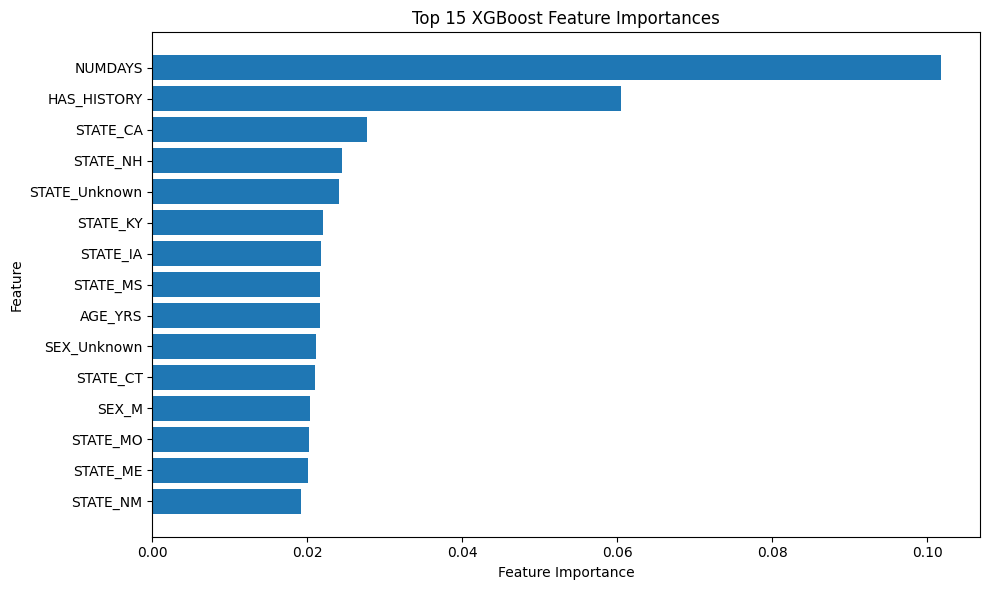

In [60]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 XGBoost Feature Importances")

plt.tight_layout()
plt.show()

In [61]:
%pip install shap


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [62]:
import shap

explainer = shap.TreeExplainer(xgb_final)
shap_values = explainer.shap_values(X_train_balanced_final)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


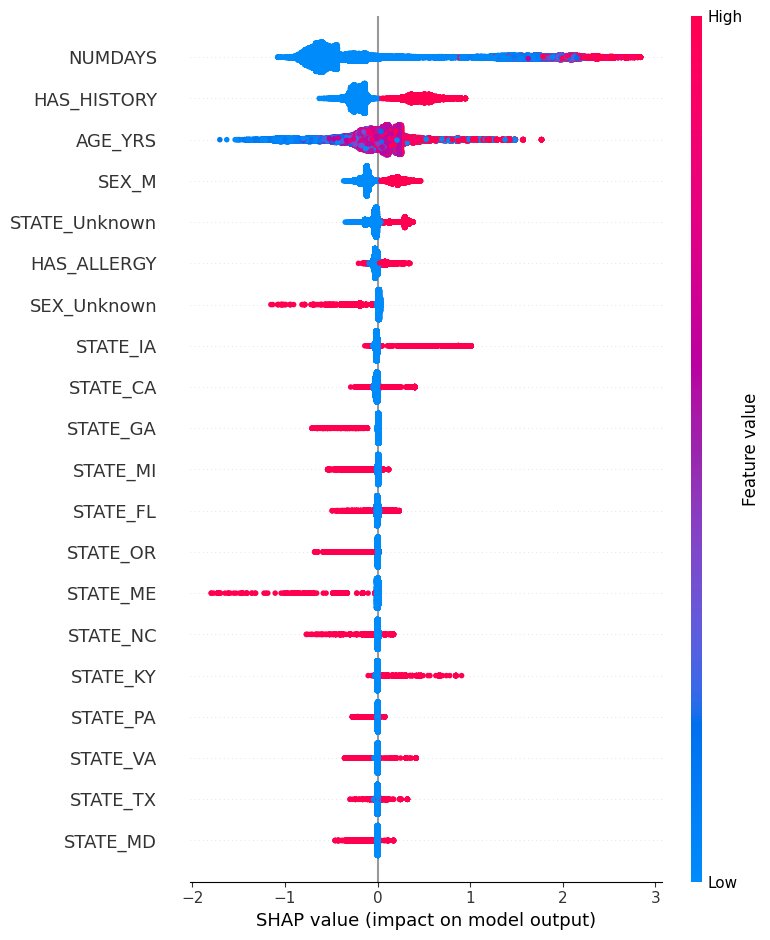

In [63]:
shap.summary_plot(
    shap_values,
    X_train_balanced_final,
    show=True
)

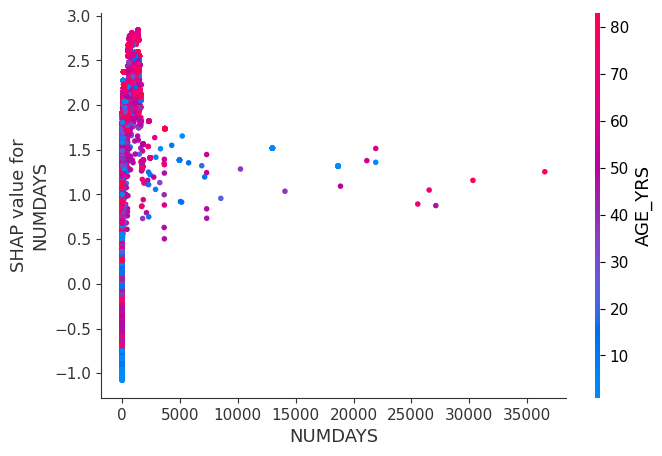

In [64]:
shap.dependence_plot(
    "NUMDAYS",
    shap_values,
    X_train_balanced_final
)

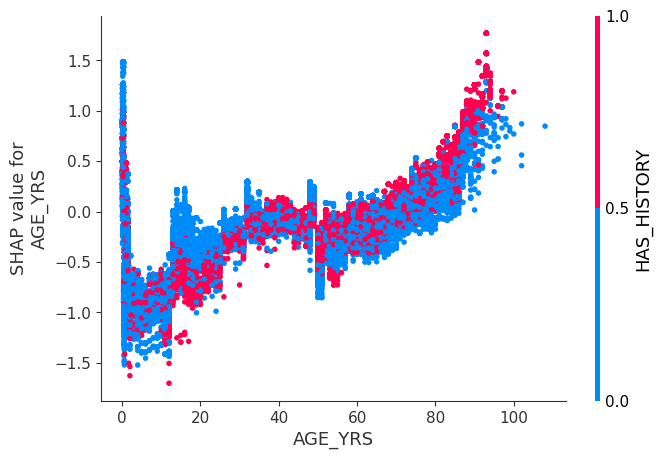

In [65]:
shap.dependence_plot(
    "AGE_YRS",
    shap_values,
    X_train_balanced_final
)

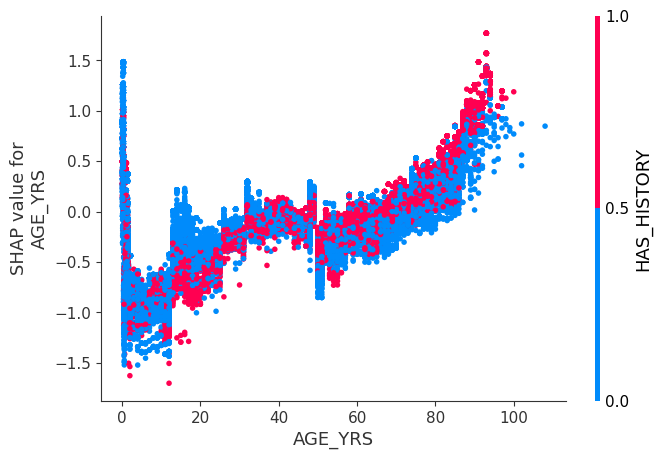

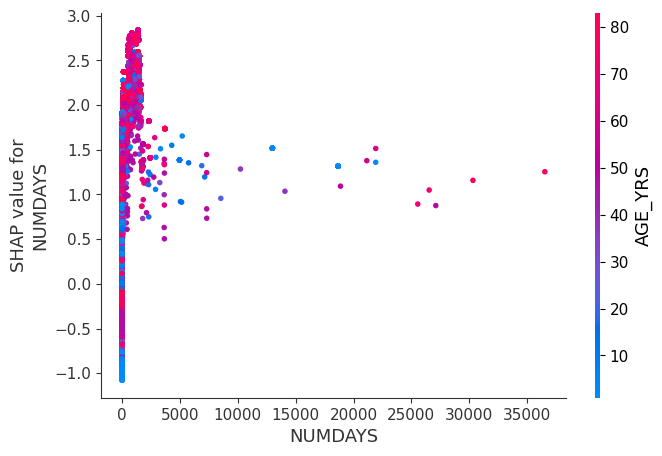

In [66]:
shap.dependence_plot(
    "AGE_YRS",
    shap_values,
    X_train_balanced_final,
    interaction_index="HAS_HISTORY"
)
shap.dependence_plot(
    "NUMDAYS",
    shap_values,
    X_train_balanced_final,
    interaction_index="AGE_YRS"
)

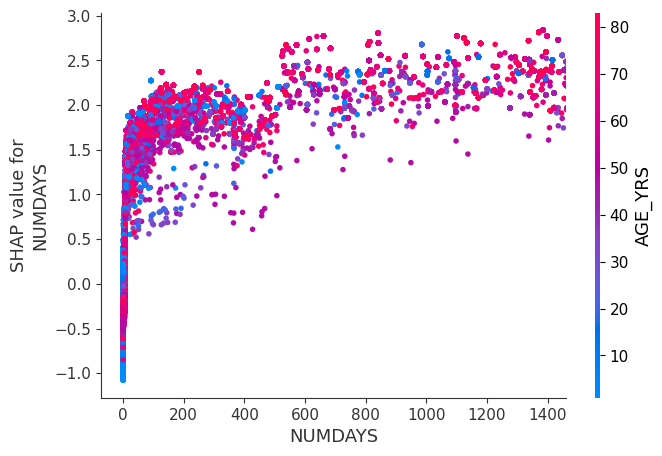

In [67]:
shap.dependence_plot(
    "NUMDAYS",
    shap_values,
    X_train_balanced_final,
    interaction_index="AGE_YRS",
    xmin="percentile(1)",
    xmax="percentile(99)"
)

**Draft: Feature Importance and Model Interpretability**

The final tuned XGBoost model's feature importance rankings were validated using SHAP (SHapley Additive exPlanations) to assess both the magnitude and directionality of each predictor's contribution to severity classification.

*Global feature importance.* Consistent with the native XGBoost feature importance scores, the SHAP summary plot confirmed that time-to-onset (`NUMDAYS`), age (`AGE_YRS`), and prior medical history (`HAS_HISTORY`) were the three most influential predictors, followed by sex and a long tail of state-level indicator variables contributing smaller, individually modest effects.

*Time-to-onset (NUMDAYS).* The relationship between `NUMDAYS` and predicted severity was strongly non-linear. SHAP values rose sharply for onset intervals within approximately the first 100–150 days post-vaccination, before continuing to increase more gradually through the remainder of the observed range (up to ~4 years). This suggests the model distinguishes most strongly between very rapid versus even moderately delayed symptom onset, with a secondary, weaker gradient distinguishing moderate from long delays.

*Age (AGE_YRS).* Age exhibited a broadly U-shaped-to-increasing relationship with predicted severity: SHAP values were near zero to mildly negative across most of childhood and adulthood, but rose sharply after approximately age 60, with the steepest increase observed above age 85. This pattern is consistent with known clinical vulnerability of older populations to adverse outcomes. An elevated cluster of SHAP values was also observed at age 0, which warrants caution in interpretation, as age values of 0 may in some cases reflect missing or unrecorded age rather than true infancy.

*Interaction effects.* Coloring the age and time-to-onset dependence plots by `HAS_HISTORY` and `AGE_YRS` respectively did not reveal strong interaction effects; contribution patterns for both features appeared largely consistent across levels of the interacting variable, suggesting these predictors act on the model's output in a mostly additive rather than interactive fashion.

*Limitations.* Two features displayed behavior warranting caution. First, `SEX_Unknown` was associated with reduced predicted severity, and `STATE_Unknown` with increased predicted severity, raising the possibility that the model is partly capturing patterns associated with data completeness rather than purely clinical signal. Second, a small number of extreme outlying values in `NUMDAYS` (exceeding 30,000 days) were identified as likely data quality artifacts rather than plausible vaccine-to-symptom intervals, and were excluded from the visualized dependence plots (though retained in model training) for interpretability purposes.


In [68]:
imbalance_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression (Original)",
        "Logistic Regression (Oversampled)",
        "Random Forest (Original)",
        "Random Forest (Oversampled)",
        "XGBoost (Original)",
        "XGBoost (Oversampled)"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_lr_balanced),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_rf_balanced),
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_xgb_balanced)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr_balanced),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf_balanced),
        precision_score(y_test, y_pred_xgb),
        precision_score(y_test, y_pred_xgb_balanced)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_lr_balanced),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf_balanced),
        recall_score(y_test, y_pred_xgb),
        recall_score(y_test, y_pred_xgb_balanced)
    ],

    "F1": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_lr_balanced),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf_balanced),
        f1_score(y_test, y_pred_xgb),
        f1_score(y_test, y_pred_xgb_balanced)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_lr_balanced),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_rf_balanced),
        roc_auc_score(y_test, y_prob_xgb),
        roc_auc_score(y_test, y_prob_xgb_balanced)
    ],

    "PR-AUC": [
        average_precision_score(y_test, y_prob_lr),
        average_precision_score(y_test, y_prob_lr_balanced),
        average_precision_score(y_test, y_prob_rf),
        average_precision_score(y_test, y_prob_rf_balanced),
        average_precision_score(y_test, y_prob_xgb),
        average_precision_score(y_test, y_prob_xgb_balanced)
    ]
})

imbalance_comparison = imbalance_comparison.round(4)
print(imbalance_comparison)

                               Model  Accuracy  Precision  Recall      F1  \
0     Logistic Regression (Original)    0.6937     0.1116  0.5627  0.1863   
1  Logistic Regression (Oversampled)    0.6928     0.1113  0.5627  0.1859   
2           Random Forest (Original)    0.8793     0.2356  0.4176  0.3013   
3        Random Forest (Oversampled)    0.8539     0.1910  0.4157  0.2617   
4                 XGBoost (Original)    0.9423     0.6900  0.1353  0.2262   
5              XGBoost (Oversampled)    0.8253     0.1941  0.5725  0.2900   

   ROC-AUC  PR-AUC  
0   0.6825  0.1970  
1   0.6807  0.1966  
2   0.7646  0.3026  
3   0.7559  0.2605  
4   0.7942  0.3431  
5   0.7845  0.3388  


In [70]:
# --- Check 1: AGE_YRS == 0 investigation ---

age_zero = data[data["AGE_YRS"] == 0]

print("Number of records with AGE_YRS == 0:", len(age_zero))
print("Percentage of total dataset:", round(100 * len(age_zero) / len(data), 2), "%")

print("\nSEVERE rate among AGE_YRS == 0:")
print(age_zero["SEVERE"].value_counts(normalize=True))

print("\nSEVERE rate overall (for comparison):")
print(data["SEVERE"].value_counts(normalize=True))

Number of records with AGE_YRS == 0: 0
Percentage of total dataset: 0.0 %

SEVERE rate among AGE_YRS == 0:
Series([], Name: proportion, dtype: float64)

SEVERE rate overall (for comparison):
SEVERE
0    0.937657
1    0.062343
Name: proportion, dtype: float64


In [71]:
# --- Check 2: NUMDAYS outlier investigation ---

numdays_outliers = data[data["NUMDAYS"] > 5000]

print("Number of records with NUMDAYS > 5000:", len(numdays_outliers))
print("Number of records with NUMDAYS > 30000:", len(data[data["NUMDAYS"] > 30000]))

print("\nSEVERE rate among NUMDAYS > 5000:")
print(numdays_outliers["SEVERE"].value_counts(normalize=True))

print("\nNUMDAYS distribution summary:")
print(data["NUMDAYS"].describe())

print("\nTop 10 largest NUMDAYS values:")
print(data.nlargest(10, "NUMDAYS")[["AGE_YRS", "NUMDAYS", "SEVERE"]])

Number of records with NUMDAYS > 5000: 36
Number of records with NUMDAYS > 30000: 2

SEVERE rate among NUMDAYS > 5000:
SEVERE
0    0.944444
1    0.055556
Name: proportion, dtype: float64

NUMDAYS distribution summary:
count    40919.000000
mean        38.467191
std        520.457629
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max      36525.000000
Name: NUMDAYS, dtype: float64

Top 10 largest NUMDAYS values:
       AGE_YRS  NUMDAYS  SEVERE
29095    79.00  36525.0       0
29299    82.00  30315.0       0
3514     75.00  27489.0       0
16479    48.00  27106.0       0
31860    72.00  26533.0       0
36963    71.00  25898.0       0
350      69.00  25547.0       0
2270     63.00  23302.0       0
28352    60.00  21916.0       0
18004     0.25  21915.0       0
